# PHerc0846A Inference

Forward-only inference of any of the three models on the PHerc0846A sheets and the other scrolls of the mix28 corpus. Set `CHECKPOINT` in the settings cell (default: the reader-v3 step 1000 of the ensemble, `utils/mix6.py` `default_models()`); the kind
of model is detected from the file (`utils/predict_models.detect_kind`) and every model reads a scroll the way it natively does:

| kind | file (the last epoch / step of its training) | reads | prediction |
|---|---|---|---|
| `HercUeNet` | `models/runs/cue_dropout_labelsv6_mix28_ps4_s1/epoch_3.pth` (`train.py`, mix28, epoch 3 of 4; `final.pth` = epoch 4) | 8 slices of a flat depth-13 surface, `DEPTH_OFFSET = -1` selects slices 9-16 | one value per 16 px cell |
| `reader_v3` | `reader-v3/runs/mix28_ps4_s1/ckpt_001000.pth` (`finetune_readerv3.py`, mix28, step 1000 of 4000) | the 17 central layers of the 28-layer render | one value per pixel |
| `v8in` | `nader-fork/runs/v8in_mix28_4ep_ps4_s1/runs/*/checkpoints/trained-epoch2.ckpt` (`finetune_v8in.py`, mix28, epoch 3 of 4) | the 24 central layers | one value per pixel |

The prize sheet is `PRIZESHEET_11_11_flatboi_flatboi_abf` (alias 20261112120000, the 2026-11-11 sheet, canonical since 2026-11-12, rendered upright; the only prize sheet, every earlier one is superseded). The figures are the same for every model:
prediction | composite of the layers that model reads, and for the 25 trained scrolls a second row with the inklabel overlay and the asf_morph cue. The inklabel is
coloured by which models trained on it (`utils/holdout_exclusion.py`): red = used by all three, orange = dropped by HercUeNet only (within 12 voxels of the prize
sheet plus its 149 px context reach), yellow = dropped by HercUeNet and v8-in (25 voxels), dark yellow = dropped by all three (reader-v3, 18 voxels). Only the
prediction changes between models; the title of each figure names the role of the patch for the
checkpoint. The depth ensembles, cue ablation, depth sweeps and denoising cells further down are specific to the HercUeNet model and are skipped for the other two.

Run the setup cells, then any individual cell: the prize sheet, the 14 trained 0846A sheets, the 14 donor patches (the three added in mix28 have their own cells), and the held-out patches (straightened2
out_4 / out_5, three quick patches). The last cell processes the remaining PHerc0846A quick patches into one `quick_patches` subfolder. Volumes and
masks must already be assembled (`python3 assemble_training_segments.py --mix28`); this notebook does not reverse volumes, detect surfaces, or modify labels.


In [1]:
import os

# [] = one depth; [low, high] = ensemble every offset low..high around the usual depth ([-3, 3] -> 7 depths); HercUeNet only
depth_ensemble = []
# how ensemble depths combine: 'z-score' (top-2), 'max', 'mid-boost' (k=3), 'mean' (top-2); '' = 'mid-boost'
ensemble_method = ''

# any of the three models (last epoch / step, utils/mix6.py MODEL_PATHS); the kind (HercUeNet | reader_v3 | v8in) is detected from the file:
#   /vesuvius/models/runs/cue_dropout_labelsv6_mix28_ps4_s1/epoch_3.pth         HercUeNet   python3 train.py (mix28, epoch 3 of 4; final.pth = epoch 4)
#   /vesuvius/reader-v3/runs/mix28_ps4_s1/ckpt_001000.pth                     reader_v3     python3 finetune_readerv3.py (mix28, step 1000 of 4000)
#   /vesuvius/nader-fork/runs/v8in_mix28_4ep_ps4_s1/runs/*/checkpoints/trained-epoch2.ckpt  v8in  python3 finetune_v8in.py (mix28, epoch 3 of 4)
# VESUVIUS_CHECKPOINT overrides CHECKPOINT (headless runs of utils/run_notebook.py)
# the default is the reader-v3 of the ensemble: step 1000 of the _ps4 run (utils/mix6.py default_models), until that exists the _ps3 run
import sys

sys.path.insert(0, "/vesuvius")
from utils import mix6

CHECKPOINT = os.environ.get("VESUVIUS_CHECKPOINT", str(mix6.default_models()["reader"]))
DEPTH_OFFSET = -1  # HercUeNet only: -1 selects slices 9-16 of the flat depth-13 surface
BATCH_SIZE = {"reader_v3": 4, "v8in": int(os.environ.get("VESUVIUS_V8IN_BATCH", 16))}  # inference batch of the two per-pixel models

FLAT_DEPTH = 13
EVAL_STRIDE = 32
PREVIEW_DOWNSCALE = 10  # previews shrink by this factor; saved figures stay full size
DEVICE = "auto"

import sys
from pathlib import Path

REPO = Path("/vesuvius")
# nonml_ink.py (imported by utils.precomputed_asf) lives in old/
for _path in (REPO, REPO / "old"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))
os.chdir(REPO)


In [2]:
# a long-lived kernel must pick up the input_cue field and the 4-cue stem before the model is built
import importlib
import utils.mix6
import utils.config
import utils.prefilter
import utils.model
import utils.predict_models

for _module in (utils.mix6, utils.config, utils.prefilter, utils.model, utils.predict_models):
    importlib.reload(_module)

In [ ]:
import gc
import json
import tempfile
import types

import cv2
import numpy as np
import torch
import zarr
from IPython.display import display
from PIL import Image

from utils import mix6, predict_models
from utils.chunk_cache import WindowVolume, read_full_zarr_threaded
from utils.fast_figure import colorize, gray_rgb, save_panel_grid
from utils.platform import get_zarr_dir

Image.MAX_IMAGE_PIXELS = None
MODEL_PATH = Path(CHECKPOINT).resolve()
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Checkpoint is missing: {MODEL_PATH}")
KIND = predict_models.detect_kind(MODEL_PATH)
ZARR_DIR = Path(get_zarr_dir())
CACHE_ROOT = REPO / "_ves_tmp" / "0846A_inference"
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

if KIND == "cue_dropout":
    from utils.config import Config, ScrollConfig, resolve_run_config
    from utils.model import create_model
    from utils.norm import (
        ANCHOR_GAP_LEVEL, ANCHOR_PAPYRUS_LEVEL, UNIFIED_CACHE_PATH,
        compute_norm, compute_surface_anchors, load_cached_norm,
    )
    from utils.visualizer import TensorboardVisualizer, predict_tiles

    RUN_CONFIG, RUN_CONFIG_PATH = resolve_run_config(MODEL_PATH)
    C = Config()
    for section in ("data", "model"):
        for name, value in RUN_CONFIG[section].items():
            if section == "data" and name == "scrolls":
                C.data.scrolls = [ScrollConfig(**item) for item in value]
            elif name != "probe_rois" and hasattr(getattr(C, section), name):
                setattr(getattr(C, section), name, value)
    C.model.compile_model = False
    C.tra.supcon = False
    C.tra.dann = False
    C.device = ("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE
    C.data.eval_stride = EVAL_STRIDE
    C.data.surface_window_offset = int(DEPTH_OFFSET)
    C.data.surface_window_offset_by_scroll = {}
    C.data.zarr_path = str(ZARR_DIR)
    DEPTH = int(C.data.depth)
    if DEPTH != 8 or not C.model.surface_teacher_input or not C.data.surface_relative_depth_window:
        raise ValueError("Select a literal-surface, eight-slice checkpoint")
    if EVAL_STRIDE <= 0 or EVAL_STRIDE > C.model.multitile_grid * C.model.multitile_subtile:
        raise ValueError("Inference stride must be positive and no larger than the prediction center")
    WINDOW_START = FLAT_DEPTH - (DEPTH - 1) // 2 + int(DEPTH_OFFSET)
    WINDOW_END = WINDOW_START + DEPTH
    NORM_MODE = str(C.data.norm_mode)
    MODEL_NAME = f"{MODEL_PATH.parent.parent.name}_{MODEL_PATH.parent.name}_{MODEL_PATH.stem}"
    OUT_DIR = REPO / "output" / "0846A" / MODEL_NAME / f"offset_{DEPTH_OFFSET:+d}"
    print(f"Model: {MODEL_PATH}\nConfig: {RUN_CONFIG_PATH}\nForward slices: {WINDOW_START}-{WINDOW_END - 1} (flat depth {FLAT_DEPTH})")
else:
    C = None
    # a Lightning checkpoint of finetune_v8in.py (runs/<run>/runs/<timestamp>/checkpoints/<epoch>.ckpt) is named by <run>
    _folder = MODEL_PATH.parents[3] if MODEL_PATH.suffix == ".ckpt" and MODEL_PATH.parent.name == "checkpoints" else MODEL_PATH.parent
    MODEL_NAME = f"{KIND}_{_folder.name}_{MODEL_PATH.stem}"
    OUT_DIR = REPO / "output" / "0846A" / MODEL_NAME
    print(f"Model: {MODEL_PATH} ({KIND}); it reads a fixed layer window of the render, nothing to configure")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# the HercUeNet model reads a flat depth-FLAT_DEPTH surface of every 0846A patch (load_inputs); detected surfaces are never used
MAIN_PATCHES = {
    "auto_grown_20261012065803387_straight_abf": {"zid": "20261012065810", "norm_id": 20261012065811},
    "auto_grown_20261012081237255_abf": {"zid": "20261012081237", "norm_id": 20261012081238},
    "auto_grown_20261014084609861_straight_abf": {"zid": "20261014084610", "norm_id": 20261014084611},
    "auto_grown_20261012065803387_straightened2_abf_out_4": {"zid": "20261012065824", "norm_id": 20261012065825},
    "auto_grown_20261012065803387_straightened2_abf_out_5": {"zid": "20261012065826", "norm_id": 20261012065827},
    # the 14 trained 0846A sheets of the mix28 corpus (utils/mix6.py SHEETS_0846A), incl. the 4 fibre neighbours of the old prize sheet
    **{name: {"zid": str(render), "norm_id": alias} for alias, (render, name) in mix6.SHEETS_0846A.items()},
}
# the 14 donor patches of mix28: their stored surface labels and window offset 0,
# not the flat depth-13 surface of the 0846A patches
DONORS = {f"{mix6.SEGMENTS[str(sid)].assembler}_{sid}": str(sid) for ids in mix6.DOMAINS.values() for sid in ids}
for _name, _sid in DONORS.items():
    MAIN_PATCHES[_name] = {"zid": _sid, "norm_id": int(_sid), "surface_dir": REPO / "surface_labels" / _sid, "offset": 0}
for patch in MAIN_PATCHES.values():
    patch["mask_dir"] = REPO / "masks"
# the PRIZE sheet (utils/mix6.py HOLDOUT, the only one): the 2026-11-11 sheet, canonical since 2026-11-12, rendered upright, flat alias 20261112120000
PRIZE_SHEET = mix6.HOLDOUT_NAME
MAIN_PATCHES[PRIZE_SHEET] = {"zid": mix6.HOLDOUT_RENDER, "norm_id": mix6.HOLDOUT, "mask_dir": REPO / "masks" / "extras"}
WINNING = PRIZE_SHEET
# every scroll the mix28 HercUeNet model trains on (utils/mix6.py): figures show the inklabel overlay and the asf_morph cue
TRAINING_NAMES = (*(name for _render, name in mix6.SHEETS_0846A.values()), *DONORS)
# held out (never trained on): straightened2 out_4 / out_5 and three quick patches
HOLDOUT_NAMES = ("auto_grown_20261012065803387_straightened2_abf_out_4",
                 "auto_grown_20261012065803387_straightened2_abf_out_5",
                 "auto_grown_20260926074031926_abf", "auto_grown_20260927143929299_abf", "auto_grown_20260927154033403_abf")
QUICK_ROOT = REPO / "tifxyz" / "quick_patches_from_D" / "PHerc0846A"
if not QUICK_ROOT.is_dir():
    raise FileNotFoundError(QUICK_ROOT)
QUICK_PATCHES = {
    path.name: {"zid": path.name, "mask_dir": REPO / "masks" / "extras"}
    for path in sorted(QUICK_ROOT.iterdir()) if path.is_dir() and (path / "x.tif").is_file()
}
INDIVIDUAL_NAMES = (WINNING, *TRAINING_NAMES, *HOLDOUT_NAMES)
PATCHES = {**QUICK_PATCHES, **MAIN_PATCHES}
REMAINING_QUICK_NAMES = tuple(name for name in QUICK_PATCHES if name not in INDIVIDUAL_NAMES)
MODEL = None


def supervision_role(name):
    patch = PATCHES[name]
    identities = {name, str(patch["zid"]), str(patch.get("norm_id", ""))}
    if KIND != "cue_dropout":  # the fine-tunes train on the mix28 corpus: the 14 0846A sheets and the labelled donors
        corpus = mix6.corpus_segments(mix6.FINETUNE_CORPUS)
        trained = {str(alias) for alias in corpus} | {mix6.render_id(alias) for alias in corpus}
        return f"TRAIN ({mix6.FINETUNE_CORPUS} corpus)" if identities & trained else "VIS-ONLY (not supervised by this checkpoint)"
    domains = C.data.train_scroll_dict or {}
    excluded = set(C.data.holdout_domains or [])
    trained = {str(sid) for domain, ids in domains.items() if domain not in excluded for sid in ids}
    if not domains:
        trained = {str(scroll.scroll_id) for scroll in C.data.scrolls}
    return "TRAIN (subject to saved label split)" if identities & trained else "VIS-ONLY (not supervised by this checkpoint)"


print(f"Output: {OUT_DIR}\nIndividual segments: {len(INDIVIDUAL_NAMES)}; remaining quick patches: {len(REMAINING_QUICK_NAMES)}")


Model: /vesuvius/reader-v3/runs/mix18/ckpt_001000.pth (reader_v3); it reads a fixed layer window of the render, nothing to configure
Output: /vesuvius/output/0846A/reader_v3_mix18_ckpt_001000
Individual segments: 31; remaining quick patches: 33


/usr/local/lib/python3.10/dist-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [4]:
# VESUVIUS_OUT_DIR puts every figure of a headless run into one folder
if os.environ.get("VESUVIUS_OUT_DIR"):
    OUT_DIR = Path(os.environ["VESUVIUS_OUT_DIR"])
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Output: {OUT_DIR}")


In [5]:
# the HercUeNet checkpoint's input heads must be replayed from its run config (strict loading fails on a 3-head model otherwise)
if KIND == "cue_dropout":
    if str(C.model.input_cue) != str(RUN_CONFIG["model"].get("input_cue") or ""):
        raise RuntimeError("input_cue was not replayed from the run config; restart the kernel")
    print("input heads:", 4 if C.model.input_cue else 3, C.model.input_cue or "(raw, lcn, dz)")
else:
    print(f"{KIND}: nothing to replay")

reader_v3: nothing to replay


In [6]:
def input_paths(name):
    patch = PATCHES[name]
    volume_path = ZARR_DIR / f"{patch['zid']}.zarr"
    mask_path = patch["mask_dir"] / f"{patch['zid']}.png"
    missing = [str(path) for path in (volume_path, mask_path) if not path.exists()]
    if missing:
        raise FileNotFoundError("Assemble these inputs before inference: " + ", ".join(missing))
    return volume_path, mask_path


# most recent patch's inputs (HercUeNet), so consecutive cells on one patch skip the reload
_INPUT_CACHE = {}

if KIND == "cue_dropout":
    def get_model():
        global MODEL
        if MODEL is None:
            model, parameter_count = create_model(C)
            state = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
            if "model_state_dict" in state:
                state = state["model_state_dict"]
            elif "state_dict" in state:
                state = state["state_dict"]
            state = {name.removeprefix("module.").removeprefix("_orig_mod."): value for name, value in state.items()}
            state = {name: value for name, value in state.items() if not name.startswith(("supcon_head.", "domain_head."))}
            model.load_state_dict(state, strict=True)
            model.eval()
            MODEL = model
            print(f"Loaded {parameter_count:,} parameters on {C.device}")
        return MODEL


    def flat_norm(patch, volume_path, mask_path, surface_depth, surface_confidence):
        if "norm_id" in patch and FLAT_DEPTH == 13:
            try:
                cached = load_cached_norm(patch["norm_id"], UNIFIED_CACHE_PATH, mode=NORM_MODE)
            except RuntimeError:
                cached = None
            if cached is not None:
                return cached
        if NORM_MODE == "raw255":
            return 0.0, 1.0, 0.0, 255.0
        private_cache = str(CACHE_ROOT / "global_norm.json")
        if NORM_MODE == "global":
            cached = load_cached_norm(patch["zid"], UNIFIED_CACHE_PATH, mode="global")
            cached = cached or load_cached_norm(patch["zid"], private_cache, mode="global")
            return cached or compute_norm(patch["zid"], str(ZARR_DIR), private_cache, mask_dir=str(patch["mask_dir"]))
        if NORM_MODE not in ("surface_anchor", "surface_anchor_knee"):
            raise ValueError(f"Unsupported normalization: {NORM_MODE}")
        attrs_path = volume_path / ".zattrs"
        signature = {
            "volume": str(volume_path.resolve()), "flat_depth": FLAT_DEPTH,
            "attrs_mtime": attrs_path.stat().st_mtime_ns if attrs_path.exists() else volume_path.stat().st_mtime_ns,
            "mask_mtime": mask_path.stat().st_mtime_ns, "shape": list(surface_depth.shape),
        }
        cache_path = CACHE_ROOT / f"{patch['zid']}_flat_anchors.json"
        if cache_path.is_file():
            cached = json.loads(cache_path.read_text())
            if cached.get("signature") == signature:
                return tuple(cached["norm"])
        with tempfile.TemporaryDirectory(dir=CACHE_ROOT) as temporary:
            surface_dir = Path(temporary) / str(patch["zid"])
            surface_dir.mkdir()
            np.save(surface_dir / "depth.npy", surface_depth)
            np.save(surface_dir / "confidence.npy", surface_confidence)
            anchors = compute_surface_anchors(patch["zid"], str(ZARR_DIR), surface_dir=temporary,
                                              mask_dir=str(patch["mask_dir"]))
        span = (anchors["papyrus"] - anchors["gap"]) / (ANCHOR_PAPYRUS_LEVEL - ANCHOR_GAP_LEVEL)
        lower = anchors["gap"] - ANCHOR_GAP_LEVEL * span
        norm = (0.0, 1.0, lower, lower + span)
        cache_path.write_text(json.dumps({"signature": signature, "norm": norm, "anchors": anchors}, indent=2))
        return norm


    def flat_cue(patch, volume, mask):
        """precomputed cue map for a model with input_cue 'pre_clahe': the stored map of the patch's flat alias when there is
        one (the exact map training read), else computed from the loaded window and cached under CACHE_ROOT/cue."""
        from utils.precomputed_asf import cue_from_window

        stored = Path(C.data.cue_dir) / f"{patch.get('norm_id', patch['zid'])}.npy"
        if stored.is_file():
            return np.load(stored, mmap_mode="r")
        cached = CACHE_ROOT / "cue" / f"{patch['zid']}_s{WINDOW_START}.npy"
        if not cached.is_file():
            cached.parent.mkdir(parents=True, exist_ok=True)
            cue = cue_from_window(np.asarray(volume[WINDOW_START:WINDOW_END], dtype=np.float32), mask)
            np.save(cached, cue)
        return np.load(cached, mmap_mode="r")


    def cue_is_flat(patch):
        """True for a scroll whose cue the checkpoint saw only as the flat map (data.cue_dropout_prob_by_scroll >= 1, utils/mix6.py CUE_DROPOUT_BY_DOMAIN)."""
        key = str(patch.get("norm_id", patch["zid"]))
        by_scroll = {int(scroll): float(share) for scroll, share in (getattr(C.data, "cue_dropout_prob_by_scroll", None) or {}).items()}
        return key.isdigit() and by_scroll.get(int(key), 0.0) >= 1.0


    def load_inputs(name):
        import time

        volume_path, mask_path = input_paths(name)
        key = (name, (volume_path / ".zarray").stat().st_mtime_ns, mask_path.stat().st_mtime_ns)
        if key in _INPUT_CACHE:
            return _INPUT_CACHE[key]
        _INPUT_CACHE.clear()
        gc.collect()
        source = zarr.open(str(volume_path), mode="r")
        if source.attrs.get("layers_reversed_from") or source.attrs.get("facing_reversed"):
            raise ValueError(f"Forward inference requires the original volume: {volume_path}")
        with Image.open(mask_path) as image:
            mask = np.asarray(image.convert("L")) > 0
        height, width = mask.shape
        if tuple(source.shape[1:]) != (height, width):
            raise ValueError(f"Mask and volume frames differ for {name}: {mask.shape} vs {source.shape}")
        if not mask.any():
            raise ValueError(f"Invalid mask for {name}")
        patch = PATCHES[name]
        offset = int(patch.get("offset", DEPTH_OFFSET))
        if patch.get("surface_dir"):
            surface_depth = np.load(Path(patch["surface_dir"]) / "depth.npy")
            surface_confidence = np.load(Path(patch["surface_dir"]) / "confidence.npy")
            if surface_depth.shape != mask.shape:
                raise ValueError(f"Surface labels {surface_depth.shape} differ from the mask {mask.shape} for {name}")
        else:
            surface_depth = np.where(mask, FLAT_DEPTH, 255).astype(np.uint8)
            surface_confidence = np.where(mask, 255, 0).astype(np.uint8)
        valid_depth = surface_depth[(surface_depth != 255) & mask]
        win_start = int(np.median(valid_depth)) - (DEPTH - 1) // 2 + offset
        win_end = win_start + DEPTH
        coords = TensorboardVisualizer._gen_tile_coords(
            types.SimpleNamespace(c=C), (C.data.d_start, C.data.d_end),
            (0, height), (0, width), mask, z_step=DEPTH,
        )
        if not coords or any(coordinate[0] != 0 for coordinate in coords):
            raise ValueError(f"Expected one nonempty surface-relative pass for {name}")
        if win_start < 0 or win_end > source.shape[0]:
            raise ValueError(f"Invalid depth window {win_start}:{win_end} for {name}")
        started = time.time()
        if patch.get("surface_dir"):
            volume = read_full_zarr_threaded(source)  # a detected surface reads a different window per pixel
        else:
            # flat surface: only the slices the (depth-ensemble) windows read are held in RAM, the zarr is read lazily otherwise
            offsets, _ = depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)
            volume = WindowVolume(source, win_start + min(offsets), win_end + max(offsets))
        print(f"[window] {name}: {volume.nbytes / 1024**3:.2f} GiB of {np.prod(source.shape) / 1024**3:.2f} GiB in RAM "
              f"in {time.time() - started:.1f}s")
        norm = flat_norm(PATCHES[name], volume_path, mask_path, surface_depth, surface_confidence)
        cue = flat_cue(PATCHES[name], volume, mask) if str(C.model.input_cue) == "pre_clahe" else None
        if cue is not None and cue_is_flat(PATCHES[name]):
            cue = np.where(np.asarray(cue) > 0, 128, 0).astype(np.uint8)  # the flat map this scroll was always trained with
            print(f"[cue] {name}: flat asf cue (this checkpoint never saw the real one on this scroll)")
        _INPUT_CACHE[key] = {"volume": volume, "mask": mask, "surface_depth": surface_depth,
                             "surface_confidence": surface_confidence, "coords": coords, "norm": norm, "cue": cue,
                             "offset": offset, "win_start": win_start, "win_end": win_end}
        return _INPUT_CACHE[key]

In [7]:
import importlib
import utils.fast_figure as figure_utils
import utils.depth_ensemble as depth_ensemble_utils
import utils.holdout_exclusion as holdout_exclusion

importlib.reload(figure_utils)
importlib.reload(depth_ensemble_utils)
importlib.reload(holdout_exclusion)
depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)

PREDICTIONS = {}  # last prediction of each rendered patch, for cells that post-process it

# inklabel colours by which models dropped the pixel (prize-sheet exclusion masks of the 0846A sheets, utils/holdout_exclusion.py
# DROP_CATEGORIES): red = kept by all three; the zones are not nested (HercUeNet 12 vx + 148 px context, v8-in 25 vx,
# reader-v3 18 vx inside v8-in), so every combination of models has its own colour


def native_inputs(name):
    """reader_v3 / v8in: papyrus mask and the max composite of the layers the model reads (no volume is held in memory)."""
    volume_path, mask_path = input_paths(name)
    source = zarr.open(str(volume_path), mode="r")
    if source.attrs.get("layers_reversed_from") or source.attrs.get("facing_reversed"):
        raise ValueError(f"Forward inference requires the original volume: {volume_path}")
    with Image.open(mask_path) as image:
        mask = np.asarray(image.convert("L")) > 0
    if tuple(source.shape[1:]) != mask.shape:
        raise ValueError(f"Mask and volume frames differ for {name}: {mask.shape} vs {source.shape}")
    start, end = predict_models.native_window(KIND, source.shape[0], MODEL_PATH)
    return volume_path, mask, start, end


def predict_native(name):
    """the per-pixel prediction (reader_v3 | v8in) of a patch, cached under CACHE_ROOT/MODEL_NAME; NaN outside the papyrus."""
    volume_path, mask, start, end = native_inputs(name)
    cache = CACHE_ROOT / MODEL_NAME / name
    if KIND == "reader_v3":
        prediction = predict_models.predict_reader(volume_path, MODEL_PATH, cache / "reader_v3.tif", BATCH_SIZE["reader_v3"])
    else:
        prediction = predict_models.predict_v8in(volume_path, MODEL_PATH, cache, BATCH_SIZE["v8in"])
    framed = np.full(mask.shape, np.nan, np.float32)
    rows, cols = min(mask.shape[0], prediction.shape[0]), min(mask.shape[1], prediction.shape[1])
    framed[:rows, :cols] = prediction[:rows, :cols]
    framed[~mask] = np.nan
    projection = np.asarray(zarr.open(str(volume_path), mode="r")[start:end]).max(axis=0)
    return framed, mask, np.clip(projection, 0, 255).astype(np.uint8) * mask, start, end


def training_label_and_cue(name, mask):
    """inklabel (dilated_inklabels) and asf_morph cue (cue_asf_morph) of a training patch, both in the mask frame."""
    patch = PATCHES[name]
    with Image.open(REPO / "dilated_inklabels" / f"{patch['norm_id']}.png") as image:
        label = np.asarray(image.convert("L")) > 0
    cue = np.load(REPO / "cue_asf_morph" / f"{mix6.volume_id(patch['norm_id'])}.npy")
    if label.shape != mask.shape or cue.shape != mask.shape:
        raise ValueError(f"{name}: mask {mask.shape}, label {label.shape}, cue {cue.shape} differ")
    return label, cue


def label_layers(name, label):
    """(mask, colour) layers of the inklabel, one per holdout_exclusion.DROP_CATEGORIES entry (who dropped the pixel)."""
    alias = PATCHES[name]["norm_id"]

    def dropped(directory):
        mask = holdout_exclusion.load(alias, label.shape, directory=directory)
        return np.zeros_like(label) if mask is None else mask

    category = holdout_exclusion.drop_category(dropped(holdout_exclusion.EXCLUSION_DIR), dropped(holdout_exclusion.READER_EXCLUSION_DIR),
                                               dropped(holdout_exclusion.V8IN_EXCLUSION_DIR))
    return [(label & (category == index), color) for index, (_name, color) in enumerate(holdout_exclusion.DROP_CATEGORIES)]


def render(name, output_subdir=None, preview=True):
    from utils.fast_figure import color_overlay, orient_display

    print(f"{name}: {supervision_role(name)}")
    if KIND == "cue_dropout":
        inputs = load_inputs(name)
        model = get_model()
        height, width = inputs["mask"].shape
        offset, WINDOW_START, WINDOW_END = inputs["offset"], inputs["win_start"], inputs["win_end"]
        offsets, method = depth_ensemble_utils.resolve(depth_ensemble, ensemble_method)
        prediction = depth_ensemble_utils.ensemble_predict(predict_tiles, offsets, method)(
            C, model, inputs["volume"], inputs["mask"], inputs["coords"],
            (0, height), (0, width), C.data.d_start, name, *inputs["norm"],
            surface_depth_map=inputs["surface_depth"],
            surface_confidence_map=inputs["surface_confidence"],
            surface_depth_offset=offset, cue_map=inputs["cue"],
        )
        prediction = np.array(prediction, dtype=np.float32)  # one value per 16 px cell
        mask = inputs["mask"]
        projection = np.asarray(inputs["volume"][WINDOW_START:WINDOW_END]).max(axis=0)
        composite = np.clip(projection, 0, 255).astype(np.uint8) * mask
        ensemble_label = depth_ensemble_utils.describe([offset + o for o in offsets], method)
        pred_interpolation = cv2.INTER_NEAREST
        del inputs, projection
    else:
        prediction, mask, composite, WINDOW_START, WINDOW_END = predict_native(name)  # one value per pixel
        ensemble_label = ""
        pred_interpolation = cv2.INTER_AREA
    PREDICTIONS[name] = prediction
    display_prediction = orient_display(prediction, name)
    display_composite = orient_display(composite, name)
    pred_title = f"{name} | {ensemble_label or f'forward {WINDOW_START}-{WINDOW_END - 1}'}"
    pred_rgb = colorize(display_prediction, "gray_r", (0.78, 0.86, 0.95))
    composite_panel = (f"composite {WINDOW_START}-{WINDOW_END - 1}", gray_rgb(display_composite), cv2.INTER_AREA, 9.362)
    if name in TRAINING_NAMES:
        # 2x2: prediction | composite over prediction + inklabel coloured by which models trained on it | asf_morph cue
        label, cue = training_label_and_cue(name, mask)
        cell_hw = display_composite.shape
        pred_full = cv2.resize(pred_rgb, (cell_hw[1], cell_hw[0]), interpolation=cv2.INTER_NEAREST)
        overlay = color_overlay(pred_full, [(orient_display(layer, name), color) for layer, color in label_layers(name, label)])
        panels = [
            [(pred_title, pred_full, cv2.INTER_AREA, None), composite_panel],
            [(f"{name} | inklabel overlay", overlay, cv2.INTER_AREA, None),
             ("asf_morph cue", gray_rgb(orient_display(cue, name)), cv2.INTER_AREA, None)],
        ]
        del pred_full, overlay, label, cue
    else:
        panels = [[(pred_title, pred_rgb, pred_interpolation, None), composite_panel]]
    folder = OUT_DIR if output_subdir is None else OUT_DIR / output_subdir
    folder.mkdir(parents=True, exist_ok=True)
    output_path = folder / f"{name}.png"
    save_panel_grid(panels, display_composite.shape, str(output_path), gap_px=24)
    if preview:
        with Image.open(output_path) as saved:
            reduced = saved.resize((max(1, saved.width // PREVIEW_DOWNSCALE),
                                    max(1, saved.height // PREVIEW_DOWNSCALE)), Image.Resampling.LANCZOS)
        display(reduced)
    print(f"Saved {output_path}")
    del prediction, composite, display_prediction, display_composite, panels
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return output_path


def render_many(names, output_subdir=None):
    """render every named patch; a failure is reported and the others still render."""
    failures, outputs = {}, []
    for index, name in enumerate(names, start=1):
        print(f"[{index}/{len(names)}] {name}")
        try:
            outputs.append(render(name, output_subdir=output_subdir))
        except Exception as error:
            failures[name] = str(error)
            print(f"FAILED {name}: {error}")
    if failures:
        raise RuntimeError(f"failures: {failures}")
    return outputs


def render_remaining_quick_patches():
    for name in REMAINING_QUICK_NAMES:
        input_paths(name)
    failures = {}
    outputs = []
    for index, name in enumerate(REMAINING_QUICK_NAMES, start=1):
        print(f"[{index}/{len(REMAINING_QUICK_NAMES)}] {name}")
        try:
            outputs.append(render(name, output_subdir="quick_patches", preview=False))
        except Exception as error:
            failures[name] = str(error)
            print(f"FAILED {name}: {error}")
    print(f"Saved {len(outputs)} quick-patch figures to {OUT_DIR / 'quick_patches'}")
    if failures:
        raise RuntimeError(f"Quick-patch failures: {failures}")
    return outputs


fiber_only_20261102b_flatboi_PRIZESHEET: VIS-ONLY (not supervised by this checkpoint)


[2026-11-03 21:58:38,352] INFO Checkpoint /vesuvius/reader-v3/runs/mix18/ckpt_001000.pth requested AMP dtype=float16 from config.mixed_precision='fp16'.


Using dimensionality (2D) from ConfigManager
Using 2D convolutions (nn.Conv2d)
Using 2D normalization (nn.InstanceNorm2d)
--- Partial autoconfiguration: using provided stage-wise settings ---
Using provided features_per_stage: [32, 64, 128, 256, 320, 320]
Detected 6 stages from features_per_stage
Patch size adjusted from (384, 384) to (384, 384) to ensure divisibility by pooling factors [32, 32]
Using provided n_blocks_per_stage: [1, 3, 4, 6, 6, 6]
Task 'ink' configured with shared decoder + head (1 channels)
NetworkFromConfig initialized with final configuration:
  model_name: ink_det
  basic_encoder_block: BasicBlockD
  basic_decoder_block: ConvBlock
  bottleneck_block: BasicBlockD
  features_per_stage: [32, 64, 128, 256, 320, 320]
  num_stages: 6
  n_blocks_per_stage: [1, 3, 4, 6, 6, 6]
  n_conv_per_stage_decoder: [1, 1, 1, 1, 1]
  kernel_sizes: [[3, 3], [3, 3], [3, 3], [3, 3], [3, 3], [3, 3]]
  pool_op_kernel_sizes: [[1, 1], [2, 2], [2, 2], [2, 2], [2, 2], [2, 2]]
  conv_op: Conv2d

[2026-11-03 21:58:45,081] INFO Loaded checkpoint /vesuvius/reader-v3/runs/mix18/ckpt_001000.pth using model weights (missing_keys=0 unexpected_keys=0)
[2026-11-03 21:58:45,403] INFO torch.compile disabled.
[2026-11-03 21:58:45,403] INFO Using device cuda for inference.
[2026-11-03 21:58:45,404] INFO Configured model source=koine_machines.training.train roi_size=384 in_chans=17 preprocessing=tifxyz_robust compile=False
[2026-11-03 21:58:45,404] INFO Running input=/dev/shm/ves_zarr_cache/fiber_only_20261102b_flatboi_PRIZESHEET.zarr output=/vesuvius/_ves_tmp/0846A_inference/reader_v3_mix18_ckpt_001000/fiber_only_20261102b_flatboi_PRIZESHEET/reader_v3.tif direction=forward
[2026-11-03 21:58:45,406] INFO Selected source layer indices=[6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
[2026-11-03 21:58:45,412] INFO Input level=0 shape=(depth=28, height=2861, width=4621) chunks=(512, 512) patch=384 stride=192 requested_overlap=0.500 blend_mode=hann tiff_tile=(384, 384) in_chans=

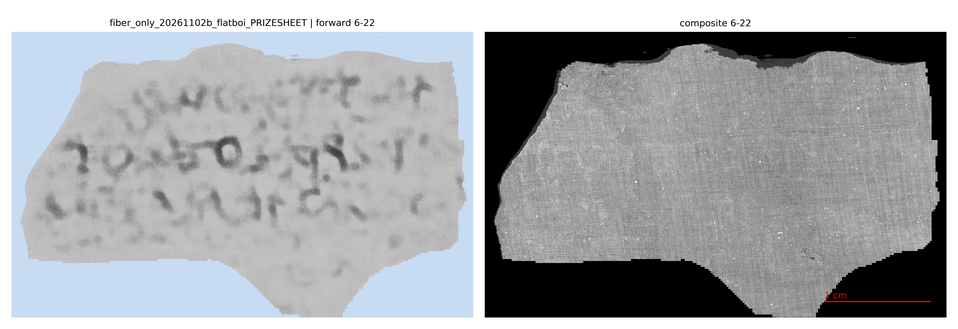

Saved /vesuvius/output/0846A/reader_v3_mix18_ckpt_001000/fiber_only_20261102b_flatboi_PRIZESHEET.png


PosixPath('/vesuvius/output/0846A/reader_v3_mix18_ckpt_001000/fiber_only_20261102b_flatboi_PRIZESHEET.png')

In [8]:
# HELD OUT PRIZE SHEET (PRIZESHEET_11_11_flatboi_flatboi_abf, upright; never trained or validated on)
render(WINNING)


In [ ]:
# TRAIN: the 11 older PHerc0846A sheets of the mix26 corpus (7 auto_grown sheets + the 4 fibre neighbours of the old prize sheet; all train only);
# the 3 sheets added 2026-11-02 have their own cells below
train_0846a_outputs = render_many([name for alias, (_render, name) in mix6.SHEETS_0846A.items() if alias not in mix6.MIX26_NEW_SHEETS])



In [ ]:
# TRAIN: abf2 fibre-only sheet (new in mix26, train only; alias 20261029130001)
render("fiber_only_abf2_20261029c_flatboi")



In [ ]:
# TRAIN: abf2 sheet moved +28 voxels along its normal (new in mix26, train only; alias 20261029130002)
render("fiber_only_abf2_20261029c_flatboi_p28")



In [ ]:
# TRAIN: PHerc0846A test surface 6 (new in mix26, train only; uint16 render; alias 20260921094415)
render("auto_grown_20260921094413486_flatboi")



In [ ]:
# TRAIN: PHerc0009B patch 642 (new in mix28, a fractured sheet; id 20250919130642)
render("p9b_642_20250919130642")


In [ ]:
# TRAIN: PHerc0009B patch 639 (new in mix28; id 20250510172639)
render("p9b_639_20250510172639")


In [ ]:
# TRAIN: PHerc0306B first-letters sheet (new in mix28; id 20261104000001; flat asf cue for the mix28 HercUeNet model)
render("p306b_letters_20261104000001")


In [ ]:
# the 11 older donor patches of mix28 (their stored surface labels, window offset 0, stored cue); the three added in mix28 have their own cells below
train_other_outputs = render_many([name for name, sid in DONORS.items() if sid not in mix6.MIX28_NEW])


In [ ]:
# HELD OUT: straightened2 out_4
render("auto_grown_20261012065803387_straightened2_abf_out_4")


In [ ]:
# HELD OUT: straightened2 out_5
render("auto_grown_20261012065803387_straightened2_abf_out_5")

In [ ]:
# HELD OUT: quick patch 20260926074031926
render("auto_grown_20260926074031926_abf")


In [ ]:
# HELD OUT: quick patch 20260927143929299
render("auto_grown_20260927143929299_abf")


In [ ]:
# HELD OUT: quick patch 20260927154033403
render("auto_grown_20260927154033403_abf")


In [ ]:
# VIS-ONLY: remaining quick patches; individual entries above are excluded.
quick_patch_outputs = render_remaining_quick_patches()